# Longitud de Arco y Curvatura

Instalar la libreria

In [ ]:
!pip install spectral

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 215.2/215.2 kB 2.9 MB/s eta 0:00:00
  Preparing metadata (setup.py) ... done
  Created wheel for spectral: filename=spectral-0.25-py3-none-any.whl size=242943 sha256=4deb018c179f3a4bceaa15b745c2223460a2a8d3c387517f6303e36235471389
  Stored in directory: /root/.cache/pip/wheels/cc/06/45/75ff8fc7bffa454fa3acd71b7a5ccf299876efaffd3f3f908c
Successfully built spectral


Importamos librerías

In [ ]:
from spectral import *
import matplotlib.pyplot as plt
import numpy as np
from google.colab import drive

Montamos el drive

In [ ]:
drive.mount('/content/drive')

Mounted at /content/drive


Cargamos la imagen

In [ ]:
ruta="/content/drive/MyDrive/PRACTICA_IMAGENES"
img=open_image(ruta+"/cartagena_test.hdr")
arr=np.asarray(img.load())
arr.shape

(725, 850, 380)

Visualizamos la imagen

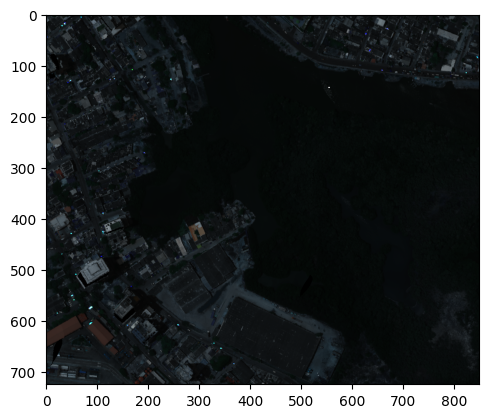

In [ ]:
view = imshow(img, (29, 50, 70))

Cargamos los puntos de muestra de asbesto, vegetación, agua, techos metalicos, tierra

In [ ]:
import pandas as pd
df_agua=pd.read_csv(ruta+"/practica_sde_ponderada/agua.csv", header=0)
df_asb=pd.read_csv(ruta+"/practica_sde_ponderada/asbesto_nuevo.csv", header=0)
df_veg=pd.read_csv(ruta+"/practica_sde_ponderada/vegetacion.csv", header=0)
df_tech=pd.read_csv(ruta+"/practica_sde_ponderada/techos_metalicos.csv", header=0)
df_carr=pd.read_csv(ruta+"/practica_sde_ponderada/carretera.csv", header=0)
df_tierr=pd.read_csv(ruta+"/practica_sde_ponderada/tierra_.csv", header=0)
df_tierr

,X,Y,Red,Green,Blue
0,187,28,92,77,63
1,188,28,93,80,66
2,186,29,86,70,57
3,187,29,87,73,60
4,188,29,96,82,68
...,...,...,...,...,...
343,255,153,122,98,76
344,251,154,97,75,59
345,252,154,116,93,71
346,253,154,124,100,76


Obtenemos una muestra representativa de los puntos

In [ ]:
import pandas as pd
df_agua=df_agua.sample(n=250,random_state=42)
df_asb=df_asb.sample(n=250,random_state=42)
df_veg=df_veg.sample(n=250,random_state=42)
df_tech=df_tech.sample(n=250,random_state=42)
df_tierr=df_tierr.sample(n=250,random_state=42)
df_carr=df_carr.sample(n=250,random_state=42)
df_carr

,X,Y,Red,Green,Blue
203,566,91,43,41,47
278,567,96,44,41,48
172,528,85,42,39,45
368,646,102,48,45,51
352,592,101,39,37,45
...,...,...,...,...,...
305,591,97,43,41,47
403,647,105,43,40,47
398,639,105,44,41,48
233,593,93,54,52,58


Convertimos los puntos a arreglos numpy

In [ ]:
punt_agua=df_agua[["X","Y"]].astype(int).to_numpy()
punt_asb=df_asb[["X","Y"]].astype(int).to_numpy()
punt_veg=df_veg[["X","Y"]].astype(int).to_numpy()
punt_tech=df_tech[["X","Y"]].astype(int).to_numpy()
punt_tierr=df_tierr[["X","Y"]].astype(int).to_numpy()
punt_carr=df_carr[["X","Y"]].astype(int).to_numpy()

Dibujamos los diferentes puntos de muestra

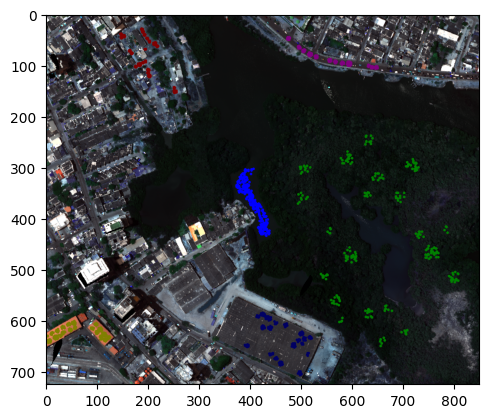

In [ ]:
import cv2
# Crear una copia de la imagen para dibujar
imagen = cv2.imread(ruta+"/cartagena_test.png")
img_copy = imagen.copy()

# Definir el radio del círculo, color (BGR) y grosor
radius = 1
thickness = 2

color = (0, 0, 100)  # Verde
# Dibujar un círculo en cada coordenada
for (x, y) in punt_asb:
      cv2.circle(img_copy, (x, y), radius, color, thickness)
color = (0, 0, 255)  # Rojo
for (x, y) in punt_agua:
    cv2.circle(img_copy, (x, y), radius, color, thickness)
color = (128, 128, 0)  # Rojo
for (x, y) in punt_tech:
    cv2.circle(img_copy, (x, y), radius, color, thickness)
color = (128, 0, 128)  # Rojo
for (x, y) in punt_carr:
    cv2.circle(img_copy, (x, y), radius, color, thickness)
color = (0, 128, 0)  # Rojo
for (x, y) in punt_veg:
    cv2.circle(img_copy, (x, y), radius, color, thickness)
color = (128, 0, 0)  # Rojo
for (x, y) in punt_tierr:
    cv2.circle(img_copy, (x, y), radius, color, thickness)
plt.imshow(img_copy,cmap='Accent')
plt.show()

Normalizamos el arreglo con la imagen

In [ ]:
max=np.max(arr)
min=np.min(arr)
arr_norm=(arr-min)/(max-min)
arr_norm

array([[[0.10853578, 0.11503612, 0.12094551, ..., 0.22055155,
         0.18988837, 0.01510177],
        [0.10958634, 0.11628365, 0.12212738, ..., 0.22376888,
         0.20636901, 0.01510177],
        [0.10840447, 0.11424819, 0.12022325, ..., 0.29960606,
         0.3232436 , 0.01510177],
        ...,
        [0.07787262, 0.08122128, 0.08417597, ..., 0.17570585,
         0.17399868, 0.01510177],
        [0.06671044, 0.06966513, 0.07321077, ..., 0.13637558,
         0.10919239, 0.01510177],
        [0.06454366, 0.06828628, 0.07261983, ..., 0.20971766,
         0.21917269, 0.01510177]],

       [[0.10722259, 0.11332896, 0.11805647, ..., 0.21352594,
         0.20347998, 0.01510177],
        [0.10682863, 0.11346027, 0.11923835, ..., 0.20157583,
         0.18319108, 0.01510177],
        [0.10663165, 0.11372291, 0.11969797, ..., 0.20840447,
         0.1827971 , 0.01510177],
        ...,
        [0.04510834, 0.04707814, 0.04812869, ..., 0.07373605,
         0.06237689, 0.01510177],
        [0.0

Creamos una lista de pixeles de asb y de otros materiales

In [ ]:
l_pix_asb=[]
l_pix_agua=[]
l_pix_veg=[]
l_pix_tech=[]
l_pix_tierr=[]
l_pix_carr=[]
for pix in punt_asb:
  l_pix_asb.append(arr_norm[pix[1],pix[0],:])
for pix in punt_agua:
  l_pix_agua.append(arr_norm[pix[1],pix[0],:])
for pix in punt_veg:
  l_pix_veg.append(arr_norm[pix[1],pix[0],:])
for pix in punt_tech:
  l_pix_tech.append(arr_norm[pix[1],pix[0],:])
for pix in punt_tierr:
  l_pix_tierr.append(arr_norm[pix[1],pix[0],:])
for pix in punt_carr:
  l_pix_carr.append(arr_norm[pix[1],pix[0],:])


Dibujamos los pixeles de asbesto

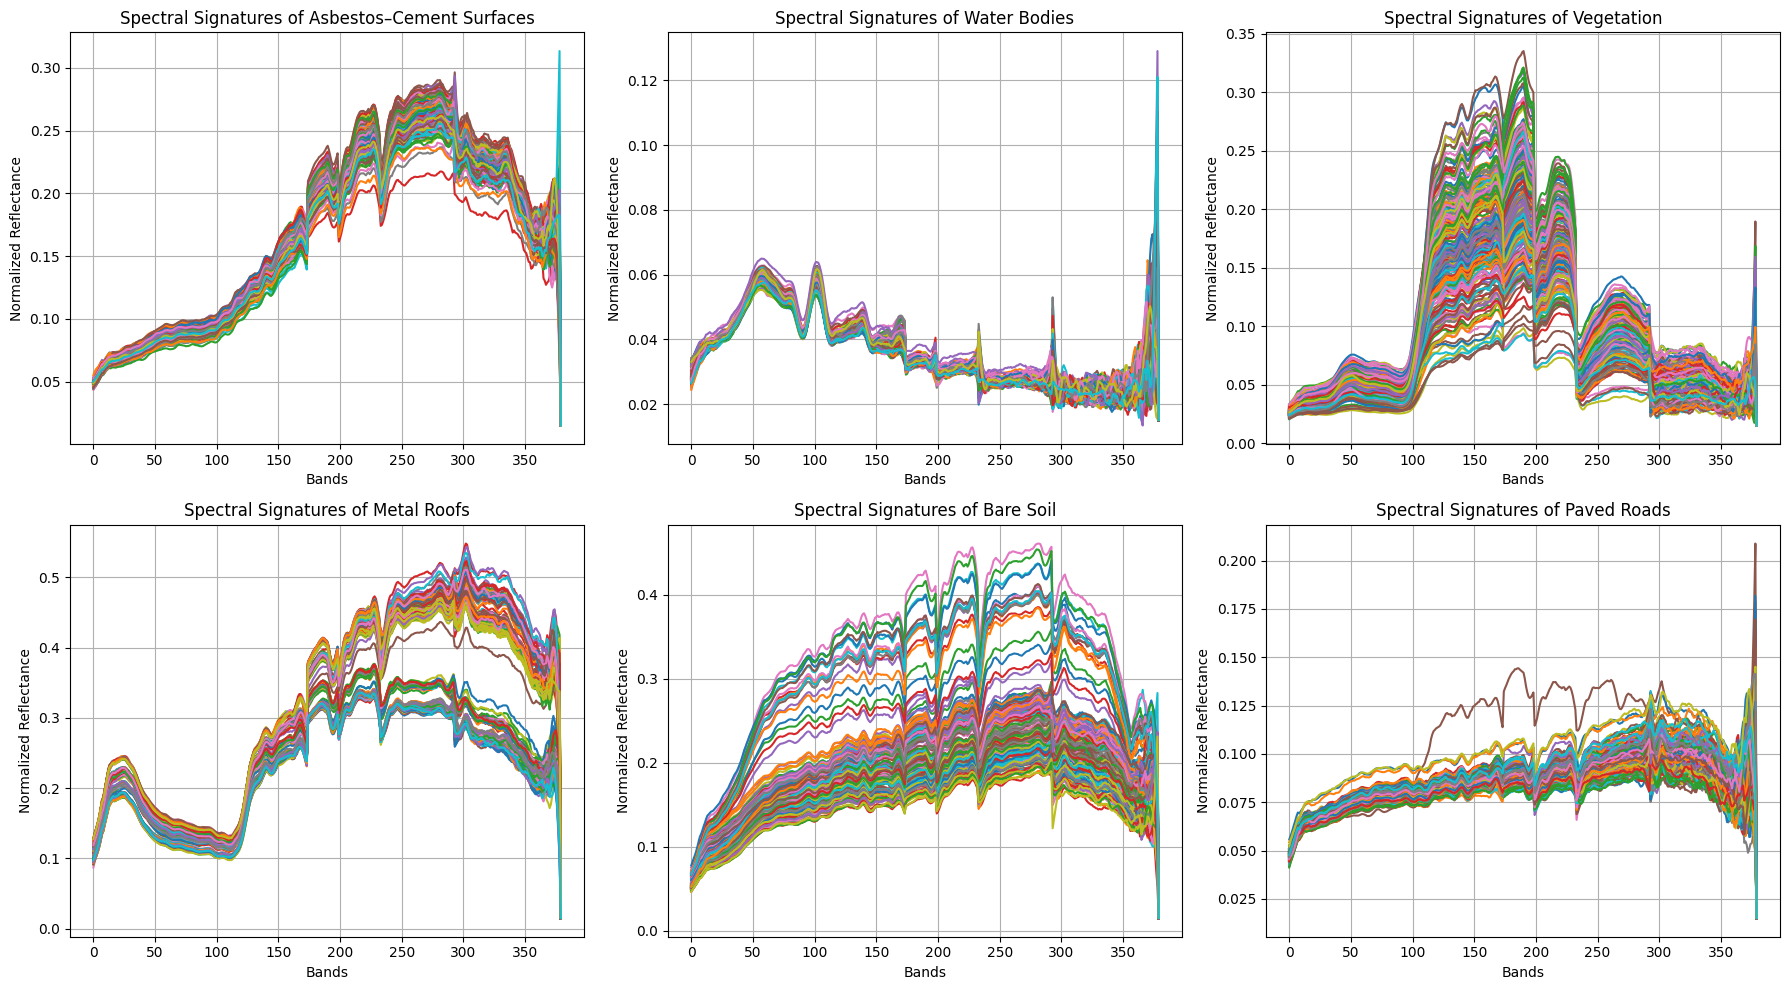

In [ ]:
import matplotlib.pyplot as plt

# Listas y títulos académicos traducidos
listas = [
    (l_pix_asb,  "Spectral Signatures of Asbestos–Cement Surfaces"),
    (l_pix_agua, "Spectral Signatures of Water Bodies"),
    (l_pix_veg,  "Spectral Signatures of Vegetation"),
    (l_pix_tech, "Spectral Signatures of Metal Roofs"),
    (l_pix_tierr,"Spectral Signatures of Bare Soil"),
    (l_pix_carr, "Spectral Signatures of Paved Roads")
]

fig, axes = plt.subplots(2, 3, figsize=(18, 10))
axes = axes.flatten()

for ax, (lista, titulo) in zip(axes, listas):
    for pix in lista:
        ax.plot(pix)

    ax.set_xlabel("Bands")
    ax.set_ylabel("Normalized Reflectance")
    ax.set_title(titulo)
    ax.grid(True)

plt.tight_layout()
plt.show()


Convertimos la listas a arreglos tipo numpy

In [ ]:
arr_asb=np.asarray(l_pix_asb)
arr_agua=np.asarray(l_pix_agua)
arr_veg=np.asarray(l_pix_veg)
arr_tech=np.asarray(l_pix_tech)
arr_tierr=np.asarray(l_pix_tierr)
arr_car=np.asarray(l_pix_carr)
arr_car

array([[0.04734077, 0.04957321, 0.05134603, ..., 0.1286277 , 0.1510834 ,
        0.01510177],
       [0.04858831, 0.05095207, 0.05279054, ..., 0.09947472, 0.10144452,
        0.01510177],
       [0.04957321, 0.05003283, 0.05101773, ..., 0.09225214, 0.1003283 ,
        0.01510177],
       ...,
       [0.04661852, 0.04845699, 0.05042679, ..., 0.14143139, 0.14123441,
        0.01510177],
       [0.05213395, 0.05508864, 0.0571241 , ..., 0.09212081, 0.07852922,
        0.01510177],
       [0.0478004 , 0.04977019, 0.05167433, ..., 0.09382797, 0.08443861,
        0.01510177]], dtype=float32)

Calculamos la firma espectral de asbesto-cemento

In [ ]:
pix_prom=np.mean(arr_asb,axis=0)
pix_prom.shape

(380,)

Graficamos el pixel de asbesto_cemento

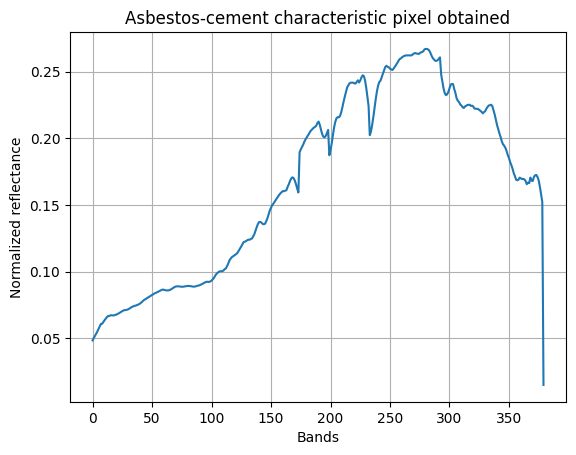

In [ ]:
plt.plot(pix_prom)
plt.xlabel("Bands")
plt.ylabel("Normalized reflectance")
plt.title("Asbestos-cement characteristic pixel obtained")
plt.grid()

# Enfoque de longitud del arco


Creamos en primera instancia el dataset

In [ ]:
import pandas as pd
import numpy as np

# Unir las 6 listas
firmas = np.concatenate([
    l_pix_asb,
    l_pix_veg,
    l_pix_agua,
    l_pix_tech,
    l_pix_tierr,
    l_pix_carr
])

# Crear etiquetas
etiquetas = (
    [1] * 250 +       # Asbesto
    [0] * 250 +       # Material 2
    [0] * 250 +       # Material 3
    [0] * 250 +       # Material 4
    [0] * 250 +       # Material 5
    [0] * 250         # Material 6
)

df = pd.DataFrame(firmas)
df['label'] = etiquetas
df.head()

,0,1,2,3,4,5,6,7,8,9,...,371,372,373,374,375,376,377,378,379,label
0,0.051149,0.053119,0.055089,0.056796,0.058175,0.059816,0.062114,0.063756,0.063559,0.065266,...,0.174590,0.174196,0.173408,0.171175,0.167827,0.162574,0.157387,0.149245,0.015102,1
1,0.048326,0.050033,0.052003,0.054563,0.056927,0.059554,0.062180,0.064281,0.064018,0.065003,...,0.171635,0.172357,0.175706,0.171569,0.165791,0.155286,0.140250,0.128234,0.015102,1
2,0.050755,0.052331,0.053578,0.054760,0.055942,0.057584,0.059554,0.061195,0.061720,0.063230,...,0.161064,0.164084,0.164544,0.163296,0.157715,0.147012,0.139790,0.124688,0.015102,1
3,0.044714,0.046422,0.048063,0.049836,0.051871,0.053775,0.055877,0.057584,0.057649,0.058634,...,0.165594,0.166645,0.168352,0.172882,0.176165,0.175049,0.174655,0.175312,0.015102,1
4,0.048063,0.050164,0.052265,0.053907,0.055614,0.057452,0.058897,0.060144,0.059882,0.060735,...,0.189232,0.191070,0.189166,0.187853,0.186343,0.174130,0.166185,0.156533,0.015102,1


Desordenamos el dataset

In [ ]:
df = df.sample(frac=1, random_state=42).reset_index(drop=True)
df.head(100)

,0,1,2,3,4,5,6,7,8,9,...,371,372,373,374,375,376,377,378,379,label
0,0.064412,0.067564,0.069665,0.072423,0.075772,0.079711,0.083322,0.086540,0.087196,0.089757,...,0.150098,0.154760,0.157058,0.161261,0.162443,0.156402,0.147341,0.138345,0.015102,0
1,0.045043,0.047012,0.048457,0.050033,0.051543,0.053185,0.054826,0.055811,0.055417,0.056467,...,0.084964,0.083651,0.085030,0.086540,0.088707,0.085686,0.083388,0.078726,0.015102,0
2,0.029087,0.029744,0.030466,0.031451,0.032502,0.033684,0.035325,0.036638,0.037229,0.037886,...,0.042285,0.044058,0.047735,0.051018,0.057846,0.055877,0.052528,0.051083,0.015102,0
3,0.028299,0.028956,0.029547,0.030401,0.031188,0.031911,0.032633,0.033224,0.033093,0.033880,...,0.044780,0.050492,0.054629,0.055483,0.054104,0.047209,0.037557,0.028956,0.015102,0
4,0.023375,0.024163,0.025016,0.025607,0.025936,0.026330,0.026724,0.026658,0.025936,0.026001,...,0.026461,0.030335,0.036179,0.045699,0.047669,0.046619,0.045043,0.042154,0.015102,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
95,0.026133,0.026592,0.026986,0.027315,0.027511,0.027577,0.027905,0.027840,0.027840,0.028102,...,0.036244,0.036704,0.036901,0.038148,0.041103,0.046947,0.052134,0.058569,0.015102,0
96,0.029416,0.030138,0.030991,0.031517,0.032502,0.033618,0.034865,0.036376,0.037032,0.038148,...,0.047932,0.051215,0.053185,0.059160,0.063033,0.067236,0.069271,0.071569,0.015102,0
97,0.046881,0.048523,0.050755,0.052397,0.054104,0.056402,0.058634,0.060538,0.060801,0.060867,...,0.138083,0.146619,0.147406,0.144846,0.139659,0.127577,0.111359,0.097177,0.015102,1
98,0.053513,0.055483,0.057190,0.058963,0.060932,0.063230,0.066448,0.068746,0.069731,0.072620,...,0.152265,0.153316,0.152725,0.152791,0.152265,0.152659,0.154104,0.157190,0.015102,0


Obtenemos los dataframes de entrenamiento y prueba

In [ ]:
from sklearn.model_selection import train_test_split

df_train, df_test = train_test_split(
    df,
    test_size=0.20,
    stratify=df['label'],
    random_state=42
)
df_train.shape

(1200, 381)

Calculamos el pixel promedio

In [ ]:
firm_asb_train = df_train[df_train['label'] == 1].drop(columns='label').to_numpy()
pix_prom_train = np.median(firm_asb_train, axis=0)

Graficamos la firma espetral promedio

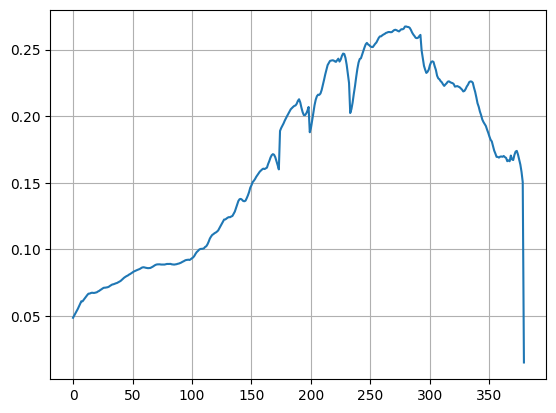

In [ ]:

plt.plot(pix_prom_train)
plt.grid()
plt.show()

Definimos una función de longitud de arco

In [ ]:
def long_arco(R):
  return np.sum(np.abs(np.diff(R)))
long_arco(pix_prom[0:100])

np.float32(0.047876466)

Aplicamos a diferentes rangos

In [ ]:
print("0-100:",long_arco(pix_prom[0:100]))
print("100-200:",long_arco(pix_prom[100:200]))
print("200-300:",long_arco(pix_prom[200:300]))
print("300-:",long_arco(pix_prom[300:]))

0-100: 0.047876466
100-200: 0.18234557
200-300: 0.22127214
300-: 0.27111253


Probamos otros rangos

In [ ]:
print("0-50:",long_arco(pix_prom[0:50]))
print("50-100:",long_arco(pix_prom[50:100]))
print("100-150:",long_arco(pix_prom[100:150]))
print("150-200:",long_arco(pix_prom[150:200]))
print("200-250:",long_arco(pix_prom[200:250]))
print("250-300:",long_arco(pix_prom[250:300]))
print("300-:",long_arco(pix_prom[300:]))

0-50: 0.0339167
50-100: 0.013432629
100-150: 0.056437552
150-200: 0.12404168
200-250: 0.15937266
250-300: 0.06084153
300-: 0.27111253


Definimos un método basado en distancia para comparar

In [ ]:
def similitud_porcentual(A, B):
  A, B = np.array(A), np.array(B)
  #Similitud por posición: 100 si iguales, 0 si muy distintos
  sims = 100 * (1 - np.abs(A - B) / (np.abs(A) + np.abs(B) + 1e-9))
  return np.mean(sims)

Obtenemos las longitudes de arco con las firmas de asbesto

In [ ]:
#lim1=150
lim1=0
lim2=100
#lim3=235
lim3=120
lim4=200
lim5=300

Graficamos los valores de la longitud de arco en diferentes rangos

55 - 0.03634275
110 - 0.018975712
165 - 0.06769534
220 - 0.16070254
275 - 0.1258043
330 - 0.08220622


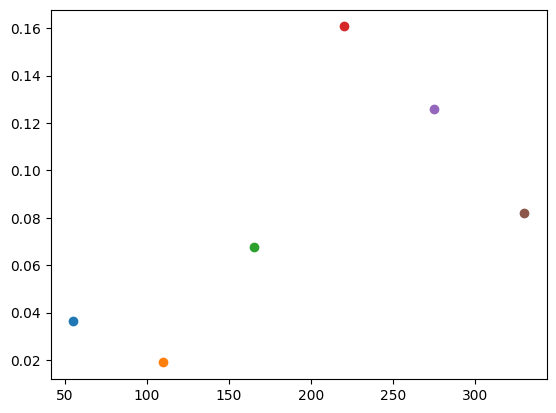

In [ ]:
l_acum=[]
for i in range(55,381,55):
  l_acum.append(long_arco(pix_prom_train[i-55:i]))
  plt.scatter(i,long_arco(pix_prom_train[i-55:i]))
  print(i,"-", long_arco(pix_prom_train[i-55:i]))
plt.show()

Obtención de la longitud de arco para el pixel promedio

In [ ]:
#120-180, 180-200
lim1=40
lim2=140
lim3=150
lim4=270
s1=long_arco(pix_prom_train[lim1:lim2])
s2=long_arco(pix_prom_train[lim3:lim4])
arr_s_prom=np.asarray([s1,s2])
print(arr_s_prom)

[0.06359159 0.30384108]


Probamos con firmas de asbesto-cemento

In [ ]:
l_arc_asb=[]
for id,row in df_train.iterrows():
  if(row['label']==1):
    pix=np.asarray(row[0:380])
    long_arco1=long_arco(pix[lim1:lim2])
    long_arco2=long_arco(pix[lim3:lim4])
    arr_s_pix=np.asarray([long_arco1,long_arco2])
    sim=similitud_porcentual(arr_s_prom,arr_s_pix)
    l_arc_asb.append(sim)
arr_arc_asb=np.asarray(l_arc_asb)
min_arc_asb=round(np.min(arr_arc_asb),3)
max_arc_asb=round(np.max(arr_arc_asb),3)
print("Min", min_arc_asb)
print("Max", max_arc_asb)

Min 92.233
Max 99.671


Probamos con firmas de otros materiales

In [ ]:
l_arc_no=[]
cont=0
for id,row in df_train.iterrows():
  if(row['label']==0):
    pix=np.asarray(row[0:380])
    long_arco1=long_arco(pix[lim1:lim2])
    long_arco2=long_arco(pix[lim3:lim4])
    arr_s_pix=np.asarray([long_arco1,long_arco2])
    sim=similitud_porcentual(arr_s_prom,arr_s_pix)
    l_arc_no.append(sim)
    if(sim<min_arc_asb):
      cont+=1
print(cont)
arr_arc_no=np.asarray(l_arc_no)
print("Min", round(np.min(arr_arc_no),3))
print("Max", round(np.max(arr_arc_no),3))

997
Min 50.928
Max 95.139


Probamos el método con el conjunto de prueba

In [ ]:
predicciones=[]
for id,row in df_test.iterrows():
  pix=np.asarray(row[0:380])
  long_arco1=long_arco(pix[lim1:lim2])
  long_arco2=long_arco(pix[lim3:lim4])
  #long_arco3=long_arco(pix[lim5:])
  arr_s_pix=np.asarray([long_arco1,long_arco2])
  sim=similitud_porcentual(arr_s_prom,arr_s_pix)
  if(sim>=min_arc_asb):
    predicciones.append(1)
  else:
    predicciones.append(0)

Creamos una nueva columna

In [ ]:
df_test['pred']=predicciones
df_test.head()

,0,1,2,3,4,5,6,7,8,9,...,372,373,374,375,376,377,378,379,label,pred
771,0.028037,0.028759,0.029481,0.030204,0.030991,0.031648,0.032436,0.033224,0.033224,0.034143,...,0.045371,0.051149,0.055154,0.058503,0.060735,0.063559,0.068877,0.015102,0,0
469,0.051346,0.053316,0.055089,0.056796,0.058306,0.060341,0.062049,0.062968,0.062246,0.063033,...,0.121536,0.128037,0.131385,0.131648,0.124622,0.116809,0.106566,0.015102,0,0
536,0.046159,0.048063,0.050164,0.052659,0.054629,0.056993,0.059422,0.061195,0.061195,0.062049,...,0.095929,0.104465,0.106960,0.104137,0.097505,0.086737,0.070716,0.015102,0,0
396,0.049114,0.050492,0.051806,0.053381,0.054760,0.056927,0.059028,0.060407,0.060276,0.062246,...,0.163690,0.163821,0.163427,0.160013,0.152331,0.148588,0.147866,0.015102,1,1
174,0.049114,0.051149,0.052922,0.054301,0.055942,0.057978,0.059816,0.061261,0.061064,0.061917,...,0.181156,0.180762,0.174721,0.164281,0.145765,0.125410,0.105515,0.015102,1,1


Calculamos las métricas

In [ ]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix
)

y_true = df_test['label']
y_pred = df_test['pred']

accuracy = accuracy_score(y_true, y_pred)
precision = precision_score(y_true, y_pred)
recall = recall_score(y_true, y_pred)
f1 = f1_score(y_true, y_pred)

cm = confusion_matrix(y_true, y_pred)

print("Accuracy :", round(accuracy,3))
print("Precision:", round(precision,3))
print("Recall   :", round(recall,3))
print("F1-score :", round(f1,3))
print("\nMatriz de confusión:")
print(cm)

Accuracy : 1.0
Precision: 1.0
Recall   : 1.0
F1-score : 1.0

Matriz de confusión:
[[250   0]
 [  0  50]]


Desplegamos ahora el método sobre la imagen

In [ ]:
arr_copia=np.copy(arr)
img_copy = imagen.copy()
tam=arr_copia.shape
cont_pix=0
for i in range(tam[0]):
  for j in range(tam[1]):
    #Obtaining the pixel i,j of the image
    pix=arr_norm[i][j]
    long_arco1=long_arco(pix[lim1:lim2])
    long_arco2=long_arco(pix[lim3:lim4])
    arr_s_pix=np.asarray([long_arco1,long_arco2])
    sim=similitud_porcentual(arr_s_prom,arr_s_pix)
    if(sim>=min_arc_asb):
      img_copy[i][j]=(0,0,128)
      cont_pix+=1
porc_pix_arc=(cont_pix/(tam[0]*tam[1]))*100
print("Percentage of Asb:", round(porc_pix_arc,3),"%")

Percentage of Asb: 11.201 %


Desplegamos sobre la imagen

ImageView object:
  Display bands       :  [0, 1, 2]
  Interpolation       :  <default>
  RGB data limits     :
    R: [np.float64(0.0), np.float64(255.0)]
    G: [np.float64(0.0), np.float64(255.0)]
    B: [np.float64(0.0), np.float64(255.0)]

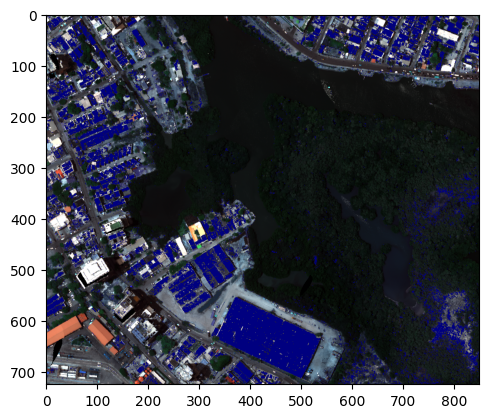

In [ ]:
view=imshow(img_copy)
view

# Curvatura

In [ ]:
def carac_curvatura(pix):
  pix = np.asarray(pix, dtype=float)
  t = np.linspace(0, 1, len(pix))
  dR = np.gradient(pix, t)
  d2R = np.gradient(dR, t)
  kappa = np.abs(d2R) / (1 + dR**2)**(3/2)
  curvatura_media = np.mean(kappa)
  curvatura_acumulada = np.trapezoid(kappa, t)
  return curvatura_acumulada
carac_curvatura(pix_prom_train)

np.float64(46.00848950120403)

Probamos diferentes tramos

In [ ]:
print("0:50",carac_curvatura(pix_prom_train[0:50]))
print("50:100",carac_curvatura(pix_prom_train[50:100]))
print("100:150",carac_curvatura(pix_prom_train[100:150]))
print("150:200",carac_curvatura(pix_prom_train[150:200]))
print("200:250",carac_curvatura(pix_prom_train[200:250]))
print("250:300",carac_curvatura(pix_prom_train[250:300]))
print("300:350",carac_curvatura(pix_prom_train[300:350]))
print("350:400",carac_curvatura(pix_prom_train[350:]))

0:50 0.3022193927700464
50:100 0.23558990848036826
100:150 0.8630652870219232
150:200 3.020959157824828
200:250 2.721902197582094
250:300 1.4158618978439743
300:350 1.2716424843883856
350:400 1.7015521429952845


Definimos los limites

lim1=45<br>
lim2=170<br>
lim3=180<br>
lim4=285<br>
Accuracy : 0.93<br>
Precision: 0.712<br>
Recall   : 0.959<br>
F1-score : 0.817<br>

Matriz de confusión:<br>
[[232  19]<br>
 [  2  47]]<br>

lim1=50<br>
lim2=150<br>
lim3=195<br>
lim4=250<br>

Accuracy : 0.94<br>
Precision: 0.731<br>
Recall   : 1.0<br>
F1-score : 0.845<br>

Matriz de confusión:<br>
[[233  18]<br>
 [  0  49]]<br>

lim1=50<br>
lim2=150<br>
lim3=195<br>
lim4=245<br>
Accuracy : 0.953<br>
Precision: 0.797<br>
Recall   : 0.959<br>
F1-score : 0.87<br>

Matriz de confusión:<br>
[[239  12]<br>
 [  2  47]]<br>


lim1=50<br>
lim2=150<br>
lim3=195<br>
lim4=240<br>

Accuracy : 0.97<br>
Precision: 0.857<br>
Recall   : 0.98<br>
F1-score : 0.914<br>

Matriz de confusión:<br>
[[243   8]<br>
 [  1  48]]<br>

In [ ]:
#lim1=50
#lim2=150
#lim3=195
#lim4=240
#927
#lim1=40
#lim2=150
#lim3=195
#lim4=240
#931
lim1=40
lim2=147
lim3=195
lim4=240
#937

Probamos con el pixel de muestra

In [ ]:
curv1_prom=carac_curvatura(pix_prom_train[lim1:lim2])
curv2_prom=carac_curvatura(pix_prom_train[lim3:lim4])
arr_curv_prom=np.asarray([curv1_prom,curv2_prom])
print(arr_curv_prom)

[2.25269602 3.05281198]


Probamos con firmas de asbesto-cemento

In [ ]:
l_curv_asb=[]
for id,row in df_train.iterrows():
  if(row['label']==1):
    pix=np.asarray(row[0:380])
    curv1=carac_curvatura(pix[lim1:lim2])
    curv2=carac_curvatura(pix[lim3:lim4])
    arr_curv=np.asarray([curv1,curv2])
    sim=similitud_porcentual(arr_curv_prom,arr_curv)
    l_curv_asb.append(sim)
arr_curv_asb=np.asarray(l_curv_asb)
min_curv_asb=round(np.min(arr_curv_asb),3)
max_curv_asb=round(np.max(arr_curv_asb),3)
print("Min", min_curv_asb)
print("Max", max_curv_asb)

Min 89.229
Max 99.852


Probamos con firmas de otros materiales

In [ ]:
l_curv_no=[]
cont=0
arr_mal=[]
for id,row in df_train.iterrows():
  if(row['label']==0):
    pix=np.asarray(row[0:380])
    curv1=carac_curvatura(pix[lim1:lim2])
    curv2=carac_curvatura(pix[lim3:lim4])
    arr_curv=np.asarray([curv1,curv2])
    sim=similitud_porcentual(arr_curv_prom,arr_curv)
    l_curv_no.append(sim)
    if(sim<min_curv_asb):
      cont+=1
print(cont)
arr_curv_no=np.asarray(l_curv_no)
print("Min", round(np.min(arr_curv_no),3))
print("Max", round(np.max(arr_curv_no),3))

937
Min 52.312
Max 98.978


Probamos con el conjunto de pruebas

In [ ]:
predicciones=[]
for id,row in df_test.iterrows():
  pix=np.asarray(row[0:380])
  curv1=carac_curvatura(pix[lim1:lim2])
  curv2=carac_curvatura(pix[lim3:lim4])
  arr_curv=np.asarray([curv1,curv2])
  sim=similitud_porcentual(arr_curv_prom,arr_curv)
  if(sim>=min_curv_asb):
    predicciones.append(1)
  else:
    predicciones.append(0)
print("Predicciones",predicciones)

Predicciones [0, 0, 0, 1, 1, 0, 1, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 1, 0, 0, 1, 0, 0, 1, 0, 0, 1, 0, 0, 1, 1, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 1, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 1, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 1, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 1, 1, 0, 0, 0, 0, 0, 1, 0, 0, 1, 1, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 1, 0, 0, 0, 0, 1, 1, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 1, 1, 0, 0, 0, 0, 0, 1, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 1, 1, 1, 1, 0, 1, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 1, 1, 0, 0, 0, 1, 0, 0, 1, 1, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 1, 1, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0]


Creamos una columna de predicciones

In [ ]:
df_test['pred_c']=predicciones
df_test.head()

,0,1,2,3,4,5,6,7,8,9,...,373,374,375,376,377,378,379,label,pred,pred_c
771,0.028037,0.028759,0.029481,0.030204,0.030991,0.031648,0.032436,0.033224,0.033224,0.034143,...,0.051149,0.055154,0.058503,0.060735,0.063559,0.068877,0.015102,0,0,0
469,0.051346,0.053316,0.055089,0.056796,0.058306,0.060341,0.062049,0.062968,0.062246,0.063033,...,0.128037,0.131385,0.131648,0.124622,0.116809,0.106566,0.015102,0,0,0
536,0.046159,0.048063,0.050164,0.052659,0.054629,0.056993,0.059422,0.061195,0.061195,0.062049,...,0.104465,0.106960,0.104137,0.097505,0.086737,0.070716,0.015102,0,0,0
396,0.049114,0.050492,0.051806,0.053381,0.054760,0.056927,0.059028,0.060407,0.060276,0.062246,...,0.163821,0.163427,0.160013,0.152331,0.148588,0.147866,0.015102,1,1,1
174,0.049114,0.051149,0.052922,0.054301,0.055942,0.057978,0.059816,0.061261,0.061064,0.061917,...,0.180762,0.174721,0.164281,0.145765,0.125410,0.105515,0.015102,1,1,1


Calculamos las métricas

In [ ]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix
)

y_true = df_test['label']
y_pred = df_test['pred_c']

accuracy = accuracy_score(y_true, y_pred)
precision = precision_score(y_true, y_pred)
recall = recall_score(y_true, y_pred)
f1 = f1_score(y_true, y_pred)

cm = confusion_matrix(y_true, y_pred)

print("Accuracy :", round(accuracy,3))
print("Precision:", round(precision,3))
print("Recall   :", round(recall,3))
print("F1-score :", round(f1,3))
print("\nMatriz de confusión:")
print(cm)

Accuracy : 0.96
Precision: 0.806
Recall   : 1.0
F1-score : 0.893

Matriz de confusión:
[[238  12]
 [  0  50]]


Desplegamos el método sobre la imagen

In [ ]:
arr_copia=np.copy(arr)
img_copy = imagen.copy()
tam=arr_copia.shape
cont_pix=0
for i in range(tam[0]):
  for j in range(tam[1]):
    #Obtaining the pixel i,j of the image
    pix=arr_norm[i][j]
    curv1=carac_curvatura(pix[lim1:lim2])
    curv2=carac_curvatura(pix[lim3:lim4])
    arr_curv=np.asarray([curv1,curv2])
    sim=similitud_porcentual(arr_curv_prom,arr_curv)
    if(sim>=min_curv_asb):
      img_copy[i][j]=(0,255,255)
      cont_pix+=1
porc_pix_curv=(cont_pix/(tam[0]*tam[1]))*100
print("Percentage of Asb:", round(porc_pix_curv,3),"%")

Percentage of Asb: 24.285 %


Visualizamos la imagen

ImageView object:
  Display bands       :  [0, 1, 2]
  Interpolation       :  <default>
  RGB data limits     :
    R: [np.float64(0.0), np.float64(255.0)]
    G: [np.float64(0.0), np.float64(255.0)]
    B: [np.float64(0.0), np.float64(255.0)]

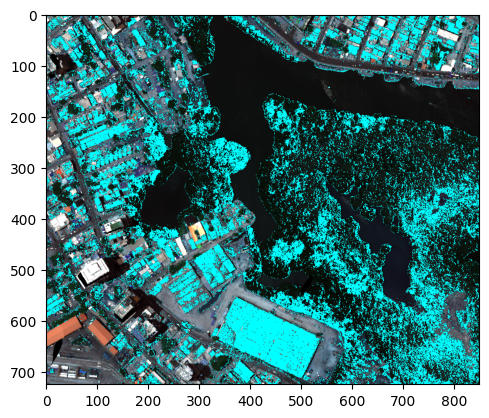

In [ ]:
view=imshow(img_copy)
view